In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
medical_dirty = pd.read_csv("realworld_medical_dirty.csv")

In [3]:
medical_clean = medical_dirty.copy()

In [4]:
medical_clean.head(5)

,Patient_ID,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes
0,P1000,55.0,FEMALE,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,NaN
1,P1001,65.0,Male,150.0,180.0,27.8,NaN,NaN,2023-01-01,NaN
2,P1002,45.0,Male,120.0,220.0,22.5,No,NaN,2023-12-14,NaN
3,P1003,65.0,Male,NaN,180.0,35.4,No,NaN,2023-07-09,NaN
4,P1004,65.0,Male,120.0,300.0,40.1,NaN,NaN,2023-07-10,Follow-up required


**Data Cleaning**

In [5]:
#1. Remove Patient_ID as a column, PII

In [6]:
medical_clean = medical_clean.drop(columns="Patient_ID")

In [7]:
#2 Change Data Type for Admission Data to date time

In [8]:
medical_clean["Admission_Date"] = pd.to_datetime(medical_clean["Admission_Date"])

In [9]:
medical_clean["Month Year"]  = (
    medical_clean["Admission_Date"].dt.month_name() + " " + medical_clean["Admission_Date"].dt.year.astype(str)
)

In [10]:
medical_clean["Year"] = medical_clean["Year"] = medical_clean["Admission_Date"].dt.year.astype(str)

In [11]:
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year
0,55.0,FEMALE,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,NaN,December 2023,2023
1,65.0,Male,150.0,180.0,27.8,NaN,NaN,2023-01-01,NaN,January 2023,2023
2,45.0,Male,120.0,220.0,22.5,No,NaN,2023-12-14,NaN,December 2023,2023
3,65.0,Male,NaN,180.0,35.4,No,NaN,2023-07-09,NaN,July 2023,2023
4,65.0,Male,120.0,300.0,40.1,NaN,NaN,2023-07-10,Follow-up required,July 2023,2023
...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,MALE,150.0,200.0,35.4,Yes,NaN,2023-07-16,Follow-up required,July 2023,2023
96,55.0,male,NaN,220.0,27.8,Y,NaN,2023-12-17,Follow-up required,December 2023,2023
97,65.0,Female,150.0,200.0,27.8,N,NaN,2023-05-13,Checkup due,May 2023,2023
98,25.0,MALE,NaN,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,2023


In [12]:
#3 fill in null values for Notes and Diagnosis and smoker 

In [13]:
medical_clean["Notes"] = medical_clean["Notes"].fillna("No Follow Up Notes")

In [14]:
medical_clean["Diagnosis"] = medical_clean["Diagnosis"].fillna("No Diagnosis")

In [15]:
medical_clean["Smoker"] = medical_clean["Smoker"].fillna("Not Sure")

In [16]:
medical_clean["Smoker"] = medical_clean["Smoker"].replace({
    "Y": "Yes",
    "N": "No"
})

In [17]:
#4 Clean up Gender Column

In [18]:
medical_clean["Gender"] = medical_clean["Gender"].fillna("Unknown")

In [19]:
medical_clean["Gender"].value_counts()

Gender
Male       22
MALE       21
Female     17
FEMALE     15
Unknown    15
male       10
Name: count, dtype: int64

In [20]:
medical_clean["Gender"] = medical_clean["Gender"].replace({
    "MALE": "Male",
    "male": "Male",
    "FEMALE": "Female"
})

In [21]:
medical_clean["Gender"] = medical_clean["Gender"].str.strip().str.title()

In [22]:
medical_clean["Gender"].value_counts()

Gender
Male       53
Female     32
Unknown    15
Name: count, dtype: int64

In [23]:
#4 check if there are nulls in the age, blood pressure, cholestrol and BMI categories, if so handle them apporiately 

In [24]:
cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]

In [25]:
null_counts = medical_clean[cols].isnull().sum()
null_pct = (null_counts / len(medical_clean) * 100).round(2)

null_summary = pd.DataFrame({
    'null_count': null_counts,
    'null_pct': null_pct
})

In [26]:
print(null_summary[null_summary['null_count'] > 0])

                null_count  null_pct
Age                     17      17.0
Blood_Pressure          14      14.0
Cholesterol             20      20.0
BMI                     20      20.0


In [27]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year
0,55.0,Female,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023
3,65.0,Male,NaN,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023


In [28]:
from scipy import stats

num_cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]
cat_cols = ["Gender", "Smoker", "Diagnosis", "Notes", "Year"]

In [29]:
rows = []
for target in num_cols:
    is_missing = medical_clean[target].isnull()

    # Categorical columns: chi-square test
    for col in cat_cols:
        table = pd.crosstab(medical_clean[col], is_missing)
        chi2, p, dof, expected = stats.chi2_contingency(table)
        rows.append({"missing_col": target, "vs": col, "test": "chi-square",
                     "p_value": round(p, 4), "min_expected": round(expected.min(), 1)})

    # Numeric columns: compare values when target is missing vs present
    for col in num_cols:
        if col == target:
            continue
        missing_grp = medical_clean.loc[is_missing, col].dropna()
        present_grp = medical_clean.loc[~is_missing, col].dropna()
        stat, p = stats.mannwhitneyu(missing_grp, present_grp)
        rows.append({"missing_col": target, "vs": col, "test": "Mann-Whitney",
                     "p_value": round(p, 4), "min_expected": None})

results = pd.DataFrame(rows).sort_values("p_value")
results

,missing_col,vs,test,p_value,min_expected
14,Blood_Pressure,Cholesterol,Mann-Whitney,0.0521,NaN
1,Age,Smoker,chi-square,0.0567,3.4
17,Cholesterol,Smoker,chi-square,0.1213,4.0
22,Cholesterol,Blood_Pressure,Mann-Whitney,0.1347,NaN
29,BMI,Age,Mann-Whitney,0.1355,NaN
31,BMI,Cholesterol,Mann-Whitney,0.1434,NaN
7,Age,BMI,Mann-Whitney,0.1458,NaN
2,Age,Diagnosis,chi-square,0.1602,4.2
8,Blood_Pressure,Gender,chi-square,0.1699,2.1
21,Cholesterol,Age,Mann-Whitney,0.1749,NaN


In [30]:
medical_clean[num_cols].isnull().corr()

,Age,Blood_Pressure,Cholesterol,BMI
Age,1.000000,-0.105877,-9.317610e-02,-9.317610e-02
Blood_Pressure,-0.105877,1.000000,-5.763904e-02,1.585074e-01
Cholesterol,-0.093176,-0.057639,1.000000e+00,1.821460e-17
BMI,-0.093176,0.158507,1.821460e-17,1.000000e+00


In [31]:
pd.crosstab(medical_clean["Smoker"], medical_clean["Age"].isnull(), normalize="index")

Age,False,True
Smoker,,
No,0.875,0.125
Not Sure,0.950,0.050
Yes,0.725,0.275


In [32]:
#5 apply median imputation to replace the null values for the numeric values 

In [33]:
for col in num_cols:
    medical_clean[f"{col}_was_missing"] = medical_clean[col].isnull()
    medical_clean[col] = medical_clean[col].fillna(medical_clean[col].median())

In [34]:
null_counts = medical_clean[cols].isnull().sum()
null_pct = (null_counts / len(medical_clean) * 100).round(2)

null_summary = pd.DataFrame({
    'null_count': null_counts,
    'null_pct': null_pct
})

In [35]:
print(null_summary[null_summary['null_count'] > 0])

Empty DataFrame
Columns: [null_count, null_pct]
Index: []


In [36]:
medical_clean.dtypes

Age                                  float64
Gender                                   str
Blood_Pressure                       float64
Cholesterol                          float64
BMI                                  float64
Smoker                                   str
Diagnosis                                str
Admission_Date                datetime64[us]
Notes                                    str
Month Year                               str
Year                                     str
Age_was_missing                         bool
Blood_Pressure_was_missing              bool
Cholesterol_was_missing                 bool
BMI_was_missing                         bool
dtype: object

In [37]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False


**Convert Month Year and Year to date formats and set to apporaite values**

In [38]:
medical_clean["Month Year"] = pd.to_datetime(medical_clean["Month Year"])
medical_clean["Month Year"] = medical_clean["Month Year"].dt.strftime("%B %Y") 

C:\Users\alexh\AppData\Local\Temp\ipykernel_8372\763906726.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  medical_clean["Month Year"] = pd.to_datetime(medical_clean["Month Year"])


In [39]:
medical_clean["Year"] = pd.to_datetime(medical_clean["Year"])
medical_clean["Year"] = medical_clean["Year"].dt.year

In [40]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False


**Create two new Column Gender_Female and Gender_Male as boolean values**

In [41]:
gender_dummies = pd.get_dummies(medical_clean["Gender"], prefix="Gender", dtype=bool)
medical_clean = medical_clean.join(gender_dummies)
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing,Gender_Female,Gender_Male,Gender_Unknown
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False,True,False,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False,False,True,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False,False,True,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False,False,True,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,Male,150.0,200.0,35.4,Yes,No Diagnosis,2023-07-16,Follow-up required,July 2023,2023,False,False,False,False,False,True,False
96,55.0,Male,140.0,220.0,27.8,Yes,No Diagnosis,2023-12-17,Follow-up required,December 2023,2023,False,True,False,False,False,True,False
97,65.0,Female,150.0,200.0,27.8,No,No Diagnosis,2023-05-13,Checkup due,May 2023,2023,False,False,False,False,True,False,False
98,25.0,Male,140.0,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,2023,False,True,False,False,False,True,False


In [42]:
medical_clean.dtypes

Age                                  float64
Gender                                   str
Blood_Pressure                       float64
Cholesterol                          float64
BMI                                  float64
Smoker                                   str
Diagnosis                                str
Admission_Date                datetime64[us]
Notes                                    str
Month Year                               str
Year                                   int32
Age_was_missing                         bool
Blood_Pressure_was_missing              bool
Cholesterol_was_missing                 bool
BMI_was_missing                         bool
Gender_Female                           bool
Gender_Male                             bool
Gender_Unknown                          bool
dtype: object

**Perform More Feature Engineering**

In [43]:
medical_clean["Missing Follow Up Notes"] = np.where(medical_clean["Notes"] == "No Follow Up Notes", True, False).astype(bool)
medical_clean["Smoking Diagnosis is Unclear"] = np.where(medical_clean["Smoker"] == "Not Sure", True, False).astype(bool)
medical_clean["Missing Diagnosis"] = np.where(medical_clean["Diagnosis"] == "No Diagnosis", True, False).astype(bool)

**Perform Feature Engineering, define blood pressure, cholestrol and bmi levels**

In [44]:
def classify_blood_pressure(bp):
    """Systolic BP categories (American Heart Association)."""
    if pd.isna(bp):
        return "Unknown"
    elif bp < 120:
        return "Normal"
    elif bp < 130:
        return "Elevated"
    elif bp < 140:
        return "Hypertension Stage 1"
    elif bp <= 180:
        return "Hypertension Stage 2"
    else:
        return "Hypertensive Crisis"


def classify_cholesterol(chol):
    """Total cholesterol categories in mg/dL (NIH / NCEP)."""
    if pd.isna(chol):
        return "Unknown"
    elif chol < 200:
        return "Desirable"
    elif chol < 240:
        return "Borderline High"
    else:
        return "High"


def classify_bmi(bmi):
    """Adult BMI categories (CDC / WHO)."""
    if pd.isna(bmi):
        return "Unknown"
    elif bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

def classify_age_group(age):
    """Age groups in 10-year bands, with 65+ as its own group."""
    if pd.isna(age):
        return "Unknown"
    elif age < 18:
        return "Under 18"
    elif age < 30:
        return "18-29"
    elif age < 40:
        return "30-39"
    elif age < 50:
        return "40-49"
    elif age < 55:
        return "50-54"
    elif age < 65:
        return "55-64"
    else:
        return "65+"

medical_clean["BP_Category"] = medical_clean["Blood_Pressure"].apply(classify_blood_pressure)
medical_clean["Cholesterol_Category"] = medical_clean["Cholesterol"].apply(classify_cholesterol)
medical_clean["BMI_Category"] = medical_clean["BMI"].apply(classify_bmi)
medical_clean["Age_Group"] = medical_clean["Age"].apply(classify_age_group)
medical_clean["Age_Group"].value_counts().sort_index()

Age_Group
18-29    11
30-39    19
40-49    11
55-64    42
65+      17
Name: count, dtype: int64

**Check for outliers in numeric columns**

In [45]:
def iqr_outliers(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return df[(df[col] < lower) | (df[col] > upper)], lower, upper

for col in num_cols:
    out, lo, hi = iqr_outliers(medical_clean, col)
    print(f"{col}: {len(out)} outliers (bounds {lo:.1f} - {hi:.1f}")

Age: 0 outliers (bounds 5.0 - 85.0
Blood_Pressure: 0 outliers (bounds 100.0 - 180.0
Cholesterol: 0 outliers (bounds 125.0 - 325.0
BMI: 0 outliers (bounds 16.4 - 46.8


**Exploratory Data Analysis**

1. return distribution of data

In [46]:
num_cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]

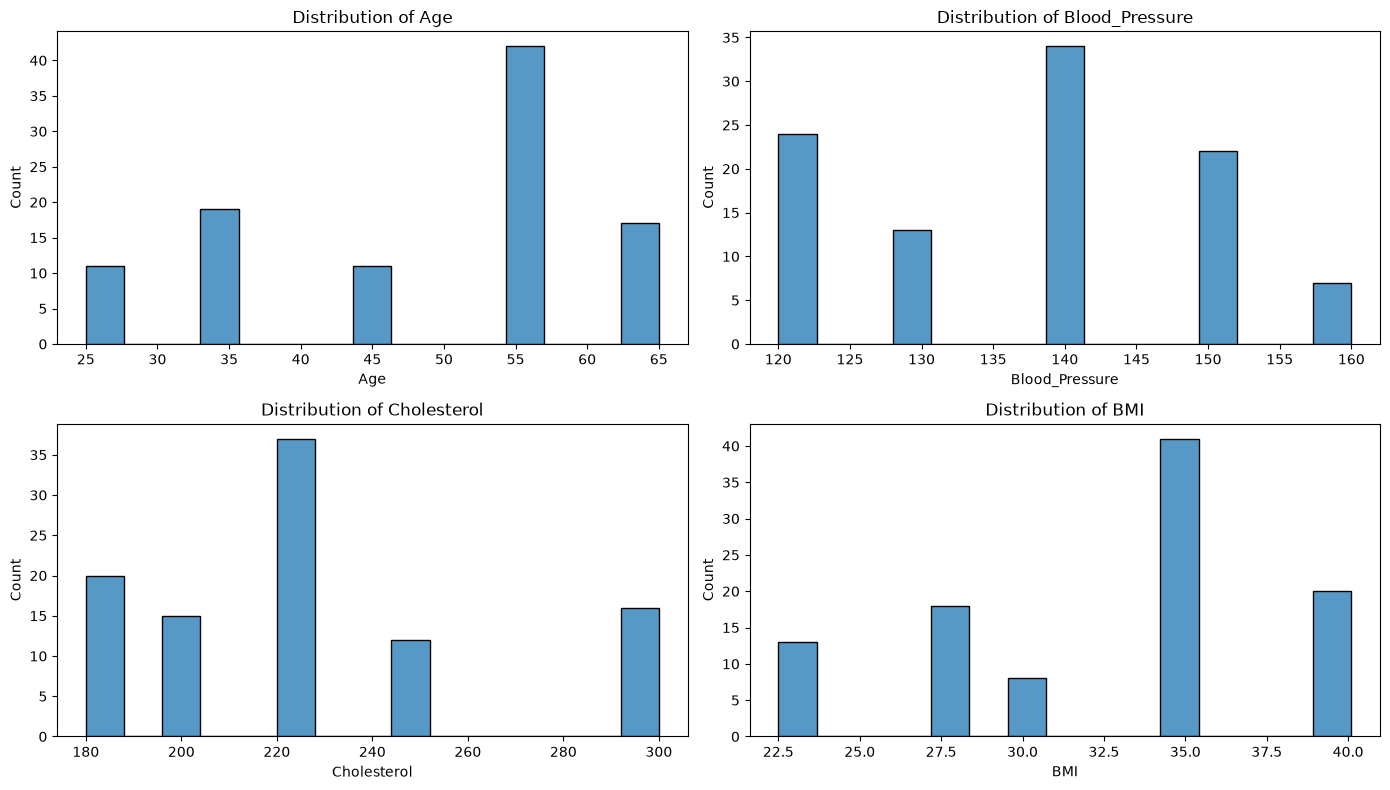

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=medical_clean, x=col, bins=15, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

2. check for correlationns between numeric columns
- none of the numeric variables are strongly correlated with another

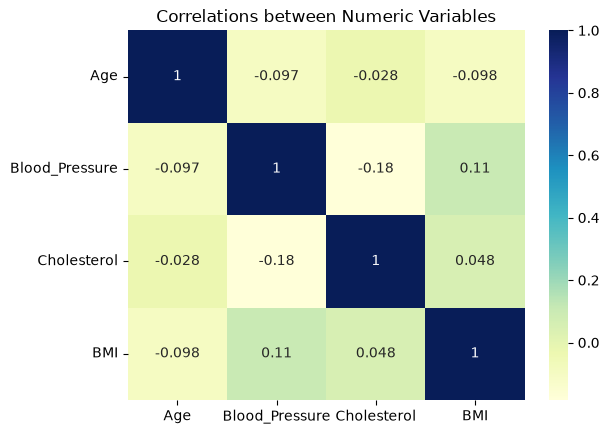

In [48]:
num_cols_corr = medical_clean[["Age", "Blood_Pressure", "Cholesterol", "BMI"]].corr(numeric_only=True)
sns.heatmap(num_cols_corr, cmap="YlGnBu", annot=True)
plt.title("Correlations between Numeric Variables")
plt.show()

In [49]:
medical_clean.dtypes

Age                                    float64
Gender                                     str
Blood_Pressure                         float64
Cholesterol                            float64
BMI                                    float64
Smoker                                     str
Diagnosis                                  str
Admission_Date                  datetime64[us]
Notes                                      str
Month Year                                 str
Year                                     int32
Age_was_missing                           bool
Blood_Pressure_was_missing                bool
Cholesterol_was_missing                   bool
BMI_was_missing                           bool
Gender_Female                             bool
Gender_Male                               bool
Gender_Unknown                            bool
Missing Follow Up Notes                   bool
Smoking Diagnosis is Unclear              bool
Missing Diagnosis                         bool
BP_Category  

In [50]:
pt = medical_clean.pivot_table(index="Diagnosis", 
                          columns=["Smoker"],
                          values="Notes",
                          aggfunc="count")

pt["Total"] = pt.sum(axis=1)

pt["Percent_Smoking"] = (
    pt["Yes"] / pt["Total"] * 100).round(2)

pt

Smoker,No,Not Sure,Yes,Total,Percent_Smoking
Diagnosis,,,,,
Diabetes,11,5,11,27,40.74
Heart Disease,10,5,10,25,40.00
No Diagnosis,19,10,19,48,39.58


In [51]:
pt1 = medical_clean.pivot_table(index="Gender",
                               columns=["Smoker"],
                               values="Notes",
                               aggfunc="count",
                               fill_value=0)

pt1["Total"] = pt1.sum(axis=1)

pt1["Percent_Smoking"] = (
    pt1["Yes"] / pt1["Total"] * 100).round(1)

pt1

Smoker,No,Not Sure,Yes,Total,Percent_Smoking
Gender,,,,,
Female,13,6,13,32,40.6
Male,20,14,19,53,35.8
Unknown,7,0,8,15,53.3


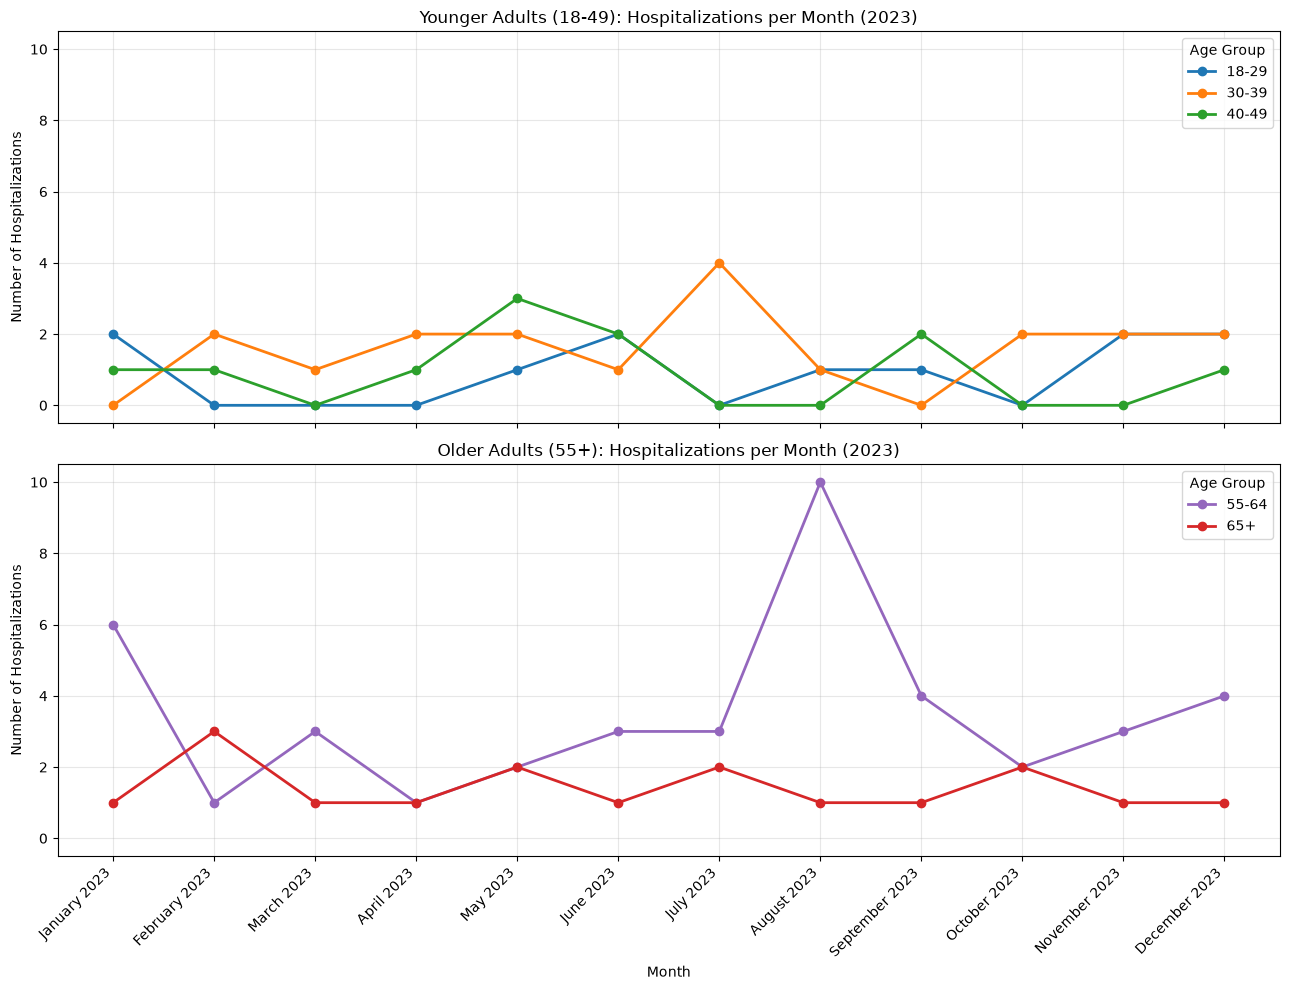

In [59]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

#showcases hospitalizations by age group by year 
age_month_counts = (
    medical_clean
    .groupby([medical_clean["Admission_Date"].dt.to_period("M"), "Age_Group"])
    .size()
    .unstack(fill_value=0)
)

age_month_counts.index = age_month_counts.index.strftime("%B %Y")

#split into two different age groups 
younger_groups = ["18-29", "30-39", "40-49"]
older_groups = ["55-64", "65+"]

# Set the legend to one unique color per group
age_colors = {
    "18-29": "#1f77b4",   # blue
    "30-39": "#ff7f0e",   # orange
    "40-49": "#2ca02c",   # green
    "55-64": "#9467bd",   # purple
    "65+":   "#d62728",   # red
}

# Two charts stacked vertically, sharing the same axes
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), sharex=True, sharey=True)

# 2. Then plot onto it, with colors
age_month_counts[younger_groups].plot(
    ax=ax1, marker="o", linewidth=2,
    color=[age_colors[g] for g in younger_groups]
)
ax1.set_title("Younger Adults (18-49): Hospitalizations per Month (2023)")
ax1.set_ylabel("Number of Hospitalizations")
ax1.legend(title="Age Group")
ax1.grid(alpha=0.3)

age_month_counts[older_groups].plot(
    ax=ax2, marker="o", linewidth=2,
    color=[age_colors[g] for g in older_groups]
)
ax2.set_title("Older Adults (55+): Hospitalizations per Month (2023)")
ax2.set_ylabel("Number of Hospitalizations")
ax2.set_xlabel("Month")
ax2.legend(title="Age Group")
ax2.grid(alpha=0.3)

ax2.set_xticks(range(len(age_month_counts)))
ax2.set_xticklabels(age_month_counts.index, rotation=45, ha="right")
ax2.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

In [60]:
diagnosis_obtained = medical_clean[medical_clean["Diagnosis"] != "No Diagnosis"]
diagnosis_obtained

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,...,Gender_Female,Gender_Male,Gender_Unknown,Missing Follow Up Notes,Smoking Diagnosis is Unclear,Missing Diagnosis,BP_Category,Cholesterol_Category,BMI_Category,Age_Group
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,...,True,False,False,True,False,False,Elevated,Borderline High,Obese,55-64
5,35.0,Female,130.0,200.0,35.4,No,Heart Disease,2023-11-08,Follow-up required,November 2023,...,True,False,False,False,False,False,Hypertension Stage 1,Borderline High,Obese,30-39
8,45.0,Male,140.0,200.0,35.4,No,Diabetes,2023-02-27,No Follow Up Notes,February 2023,...,False,True,False,True,False,False,Hypertension Stage 2,Borderline High,Obese,40-49
9,65.0,Male,130.0,220.0,35.4,No,Diabetes,2023-02-13,Checkup due,February 2023,...,False,True,False,False,False,False,Hypertension Stage 1,Borderline High,Obese,65+
12,55.0,Male,160.0,180.0,27.8,Yes,Diabetes,2023-06-22,No Follow Up Notes,June 2023,...,False,True,False,True,False,False,Hypertension Stage 2,Desirable,Overweight,55-64
15,55.0,Male,140.0,250.0,30.0,No,Diabetes,2023-05-29,Checkup due,May 2023,...,False,True,False,False,False,False,Hypertension Stage 2,High,Obese,55-64
17,55.0,Female,130.0,220.0,27.8,Yes,Diabetes,2023-08-01,Follow-up required,August 2023,...,True,False,False,False,False,False,Hypertension Stage 1,Borderline High,Overweight,55-64
20,65.0,Male,140.0,220.0,35.4,No,Diabetes,2023-08-17,Follow-up required,August 2023,...,False,True,False,False,False,False,Hypertension Stage 2,Borderline High,Obese,65+
22,55.0,Unknown,120.0,180.0,27.8,No,Diabetes,2023-08-15,No Follow Up Notes,August 2023,...,False,False,True,True,False,False,Elevated,Desirable,Overweight,55-64
23,35.0,Female,120.0,250.0,35.4,Yes,Diabetes,2023-05-27,No Follow Up Notes,May 2023,...,True,False,False,True,False,False,Elevated,High,Obese,30-39


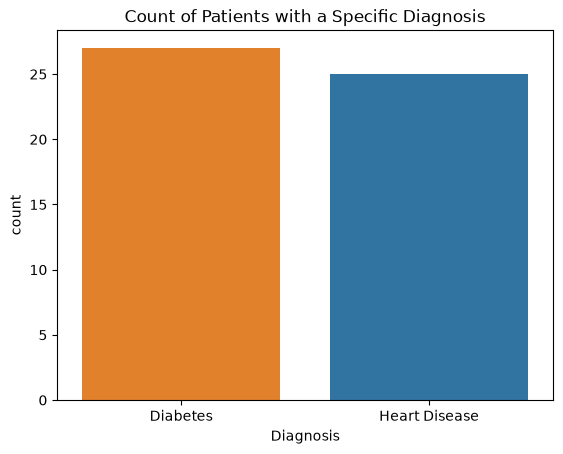

In [63]:
order1 = diagnosis_obtained["Diagnosis"].value_counts().index
sns.countplot(data=diagnosis_obtained, x="Diagnosis", order=order1, hue="Diagnosis")
plt.title("Count of Patients with a Specific Diagnosis")
plt.show()

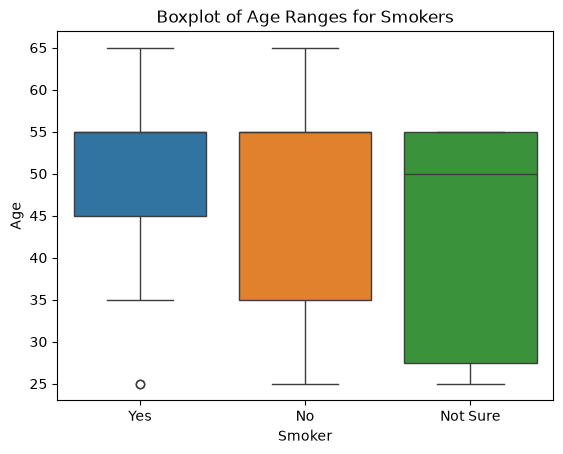

In [72]:
sns.boxplot(data=diagnosis_obtained, x="Smoker", y="Age", hue="Smoker")
plt.title("Boxplot of Age Ranges for Smokers")
plt.show()

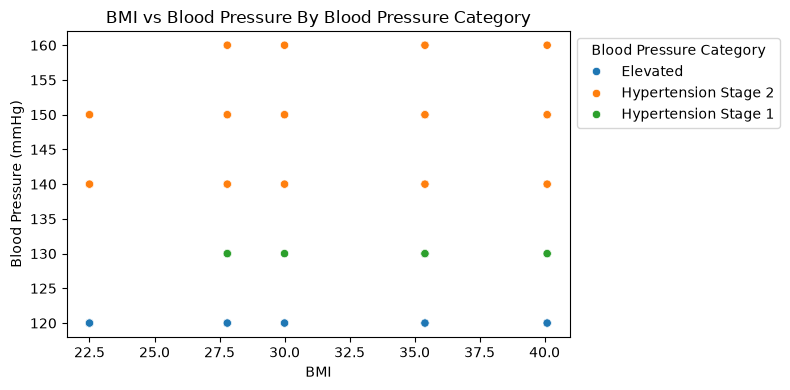

In [90]:
plt.subplots(figsize=(8, 4))
ax = sns.scatterplot(data=medical_clean, x="BMI", y="Blood_Pressure", hue="BP_Category")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="Blood Pressure Category")
ax.set_ylabel("Blood Pressure (mmHg)")
ax.set_title("BMI vs Blood Pressure By Blood Pressure Category")
plt.tight_layout()
plt.show()